# Quick check of the extracted nodule cubes (LNDb + LIDC)

Sanity notebook for the **cube extraction** step. It takes a tiny random
sample of the nodule cubes produced by the two preprocessing scripts and

1. counts how many volumes and masks each output directory holds,
2. prints basic properties of the sampled cubes (size, spacing, physical
   size, dtype, HU range, mask size) and runs a few automatic sanity
   checks (plausible HU, correct dtype, mask present, matching shapes),
3. displays axial slices of every sampled cube with the mask overlaid.

Run it **after** the preprocessing scripts:

* `python -m src.mass_detect.scripts.lndb_preprocessing`  -> LNDb cubes
* `python -m src.mass_detect.scripts.lidc_preprocessing`    -> LIDC cubes

Nothing here feeds the later pipeline — it only exists to eyeball that the
cubes are CT volumes (HU values, not mask codes) and that the masks sit
inside them.

The cubes are read from where the scripts actually write them (both default
under `data/nodules/`; change the entries in the configuration cell if you
move the outputs):

* LNDb: `data/nodules/train/` (or `test/`) — `LNDb-XXXX_noduleYYY.mhd` + `_mask.mhd`
* LIDC: `data/nodules/` (flat) — `LIDC-IDRI-XXXX_noduleY.mhd` + `_mask.mhd`


In [1]:
# ============================================================
# CONFIGURATION — change paths and sample size here
# ============================================================
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk

# ---------- path handling ----------
# Notebooks are executed either from the repository root (jupyter) or from
# notebooks/ (nbconvert uses the notebook's directory as the working
# directory), so relative paths are resolved against the repository root.
def _repo_root():
    here = Path.cwd()
    return here if (here / "pyproject.toml").exists() else here.parent

REPO_ROOT = _repo_root()

def _resolve(path):
    """Relative paths are resolved against the repository root."""
    path = Path(path)
    return path if path.is_absolute() else REPO_ROOT / path

# ---------- cube directories ----------
# Outputs of the two preprocessing scripts (both default under data/nodules/):
#   lndb_preprocessing.py -> <out-dir>/<split>/  (LNDb-XXXX_noduleYYY.mhd + _mask.mhd)
#   lidc_preprocessing.py   -> OUTPUT_DIR, flat    (LIDC-IDRI-XXXX_noduleY.mhd + _mask.mhd)
# (dataset label, directory) — add or change entries here to check other
# splits/datasets.
CUBE_DIRS = [
    ("LNDb", "data/nodules/train"),
    ("LIDC", "data/nodules"),
]

# ---------- sample ----------
SAMPLE_PER_DATASET = 3   # a handful of cubes is enough for a visual check
SEED = 42                # reproducible sample

# ---------- display ----------
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 160)
print("configuration loaded")


configuration loaded


In [2]:
def find_cubes(directory):
    """List the nodule volumes in one cube directory and their masks.

    Same naming convention as extract_features_pyrad.py: a volume is every
    *.mhd whose name does not contain "mask", and its mask is the sibling
    file <name>_mask.mhd.
    """
    volumes = sorted(p for p in directory.glob("*.mhd") if "mask" not in p.name)
    rows = []
    for vol in volumes:
        mask = vol.with_name(vol.stem + "_mask.mhd")
        rows.append({"nodule_id": vol.stem, "volume": vol,
                     "mask": mask if mask.exists() else None})
    return pd.DataFrame(rows)

cubes = {}
for dataset, path in CUBE_DIRS:
    path = _resolve(path)
    if not path.is_dir():
        print(f"[warn] {path} does not exist yet — run the preprocessing script first")
        cubes[dataset] = pd.DataFrame(columns=["nodule_id", "volume", "mask"])
        continue
    cubes[dataset] = find_cubes(path)
    n_no_mask = int(cubes[dataset]["mask"].isna().sum())
    msg = f"{dataset}: {len(cubes[dataset])} volumes in {path}"
    if n_no_mask:
        msg += f"   !! {n_no_mask} of them have no _mask.mhd"
    print(msg)


LNDb: 592 volumes in /home/adp/aulas_wsl/LabIACD/Project1/mass_detect/data/nodules/train
LIDC: 1987 volumes in /home/adp/aulas_wsl/LabIACD/Project1/mass_detect/data/nodules


In [3]:
# A tiny random sample is enough for a visual check.
rng = np.random.default_rng(SEED)
sample = {}
for dataset, df in cubes.items():
    if len(df) == 0:
        sample[dataset] = df
        continue
    pick = rng.choice(len(df), size=min(SAMPLE_PER_DATASET, len(df)), replace=False)
    sample[dataset] = df.iloc[pick].reset_index(drop=True)


def describe_cube(row):
    """Read one cube and return its basic properties and any failed checks."""
    img = sitk.ReadImage(str(row["volume"]))
    vol = sitk.GetArrayFromImage(img)      # (z, y, x)
    sx, sy, sz = img.GetSpacing()          # (x, y, z)
    size = img.GetSize()

    mask, mask_values = None, None
    if not pd.isna(row["mask"]):
        mask = sitk.GetArrayFromImage(sitk.ReadImage(str(row["mask"])))
        mask_values = np.unique(mask)

    props = {
        "size_vox": f"{size[0]}x{size[1]}x{size[2]}",
        "spacing_mm": f"{sx:.3f}x{sy:.3f}x{sz:.3f}",
        "physical_mm": f"{size[0]*sx:.0f}x{size[1]*sy:.0f}x{size[2]*sz:.0f}",
        "isotropic": "yes" if np.allclose((sx, sy, sz), sx, rtol=0.05) else "no",
        "dtype": img.GetPixelIDTypeAsString(),
        "HU_min": float(vol.min()),
        "HU_max": float(vol.max()),
        "HU_mean": round(float(vol.mean()), 1),
        "mask_voxels": int((mask > 0).sum()) if mask is not None else "no mask",
        "mask_mm3": round(float((mask > 0).sum() * sx * sy * sz), 1) if mask is not None else "",
        "mask_values": (", ".join(str(int(v)) for v in mask_values[:5])
                        if mask is not None else ""),
    }

    # Automatic sanity checks; failures are printed below the table.
    failed = []
    if mask is not None and mask.shape != vol.shape:
        failed.append("volume and mask have different sizes")
    if not all(s > 0 for s in (sx, sy, sz)):
        failed.append("non-positive spacing")
    if not (-3000.0 <= float(vol.min()) and float(vol.max()) <= 3000.0):
        failed.append("HU values outside the plausible range [-3000, 3000]")
    # A CT volume is stored as 16-bit integers spanning air (~-1024) up to
    # dense tissue; a mask patch is 8-bit with a handful of small values.
    if (img.GetPixelIDTypeAsString().startswith("8-bit")
            and float(vol.min()) >= 0 and float(vol.max()) <= 10):
        failed.append("volume looks like a MASK patch, not a CT volume")
    return props, failed


rows, failures = [], {}
for dataset, df in sample.items():
    for _, row in df.iterrows():
        props, failed = describe_cube(row)
        props = {"dataset": dataset, "nodule_id": row["nodule_id"], **props}
        rows.append(props)
        if failed:
            failures[props["nodule_id"]] = failed

props_df = pd.DataFrame(rows)[
    ["dataset", "nodule_id", "size_vox", "spacing_mm", "physical_mm", "isotropic",
     "dtype", "HU_min", "HU_max", "HU_mean", "mask_voxels", "mask_mm3", "mask_values"]]

print(f"sampled {len(props_df)} cubes "
      + ", ".join(f"({dataset}: {len(df)})" for dataset, df in sample.items()))
if failures:
    print(f"\n{len(failures)} cube(s) FAILED a sanity check:")
    for nodule_id, failed in failures.items():
        for problem in failed:
            print(f"  [FAIL] {nodule_id}: {problem}")
else:
    print("all sanity checks passed")

props_df


sampled 6 cubes (LNDb: 3), (LIDC: 3)
all sanity checks passed


,dataset,nodule_id,size_vox,spacing_mm,physical_mm,isotropic,dtype,HU_min,HU_max,HU_mean,mask_voxels,mask_mm3,mask_values
0,LNDb,LNDb-0179_nodule002,56x56x30,0.540x0.540x1.000,30x30x30,no,16-bit signed integer,-1320.0,410.0,-488.5,138,40.2,"0, 1"
1,LNDb,LNDb-0017_nodule006,44x44x30,0.705x0.705x1.000,31x31x30,no,16-bit signed integer,-1024.0,1068.0,-562.6,72,35.8,"0, 1"
2,LNDb,LNDb-0240_nodule002,52x52x30,0.586x0.586x1.001,30x30x30,no,16-bit signed integer,-1247.0,1142.0,-753.9,119,40.9,"0, 1"
3,LIDC,LIDC-IDRI-0061_nodule005,15x68x63,2.500x0.820x0.820,38x56x52,no,16-bit signed integer,-1010.0,848.0,-461.9,10639,17897.8,"0, 1"
4,LIDC,LIDC-IDRI-0709_nodule003,3x30x31,3.000x0.540x0.540,9x16x17,no,16-bit signed integer,-1037.0,886.0,-505.3,113,98.9,"0, 1"
5,LIDC,LIDC-IDRI-0861_nodule001,10x79x57,3.000x0.652x0.652,30x52x37,no,16-bit signed integer,-999.0,137.0,-364.7,2458,3138.0,"0, 1"


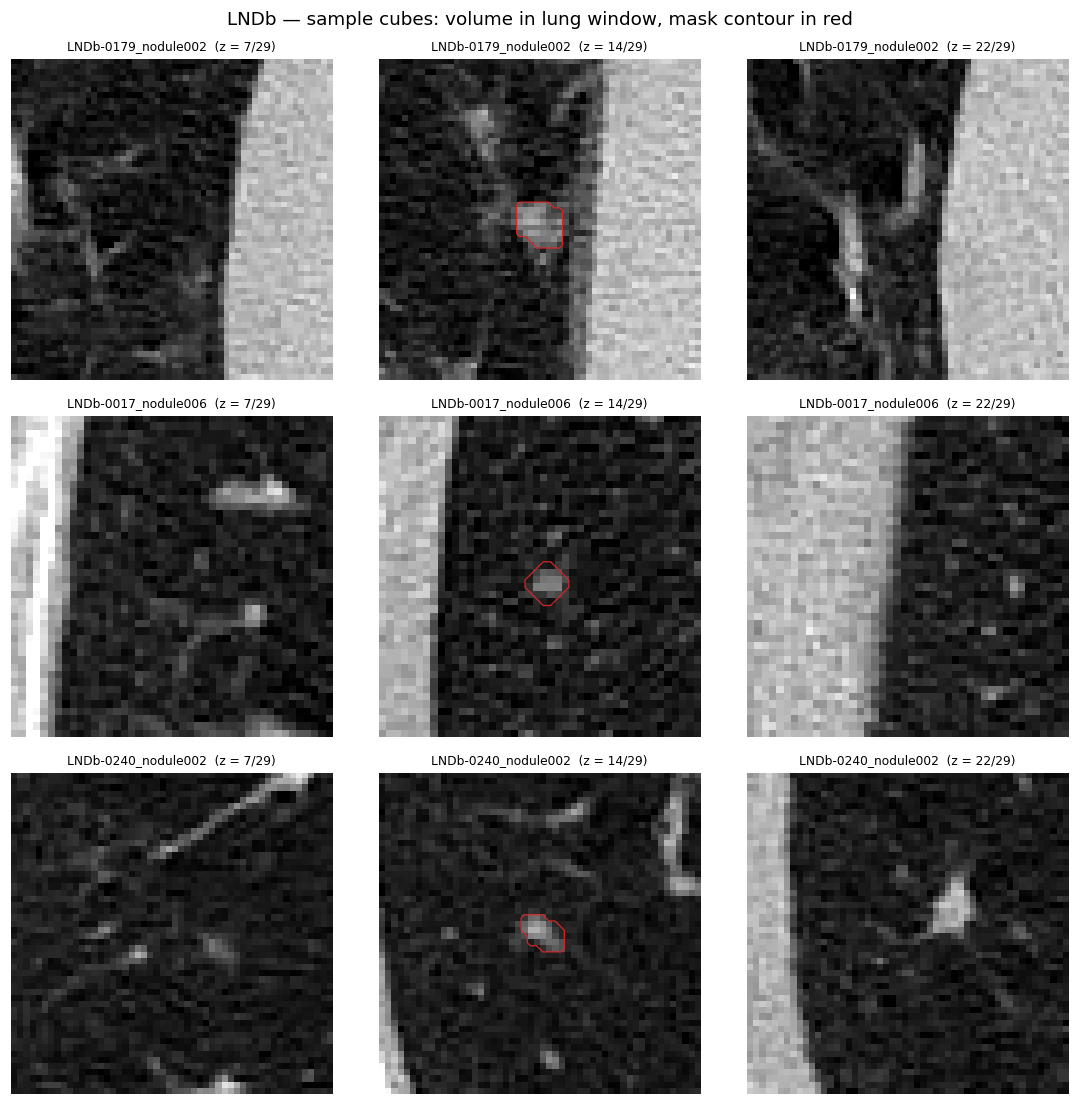

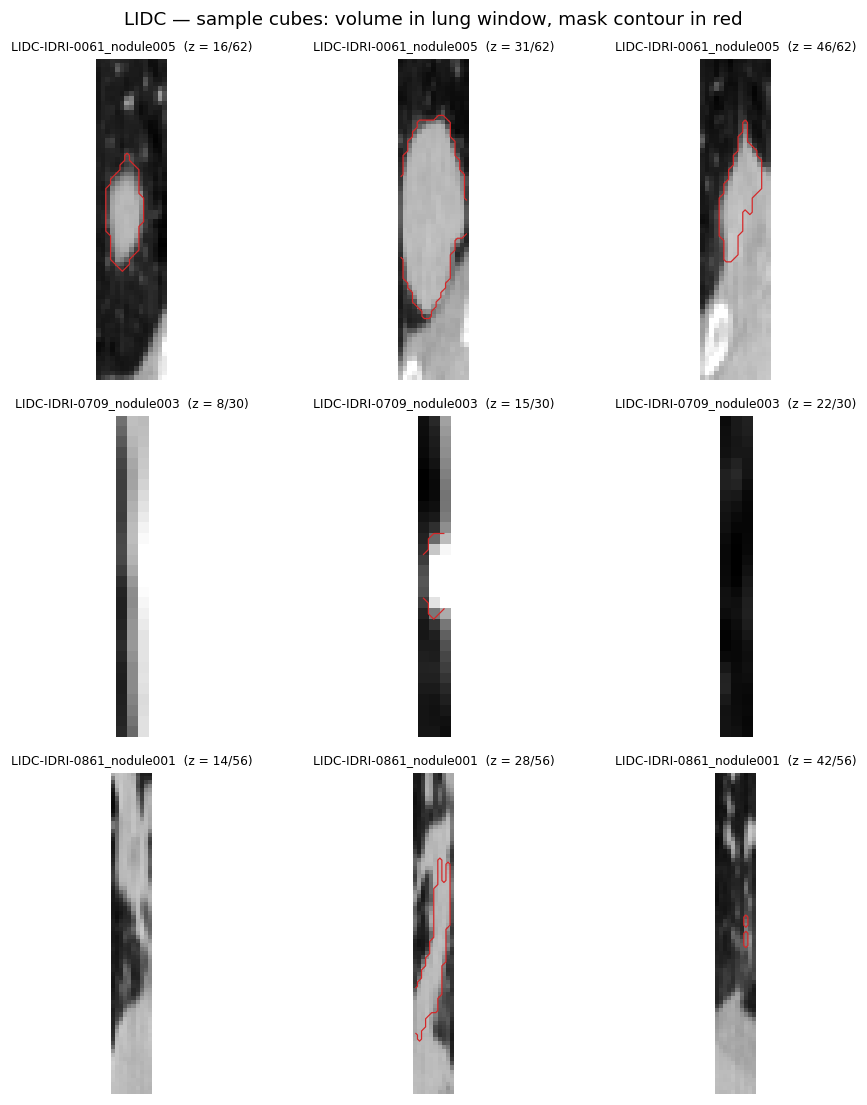

In [4]:
# Display only: lung window, and the axial slices to show (as a fraction of z).
WINDOW = (-1000.0, 400.0)
SLICES = (0.25, 0.5, 0.75)

for dataset, df in sample.items():
    if len(df) == 0:
        print(f"{dataset}: nothing to display")
        continue
    fig, axes = plt.subplots(len(df), len(SLICES),
                             figsize=(3.4 * len(SLICES), 3.4 * len(df)))
    axes = np.asarray(axes).reshape(len(df), len(SLICES))
    for i, (_, row) in enumerate(df.iterrows()):
        vol = sitk.GetArrayFromImage(sitk.ReadImage(str(row["volume"]))).astype(np.float32)
        if pd.isna(row["mask"]):
            mask = None
        else:
            mask = sitk.GetArrayFromImage(sitk.ReadImage(str(row["mask"]))) > 0
        z = vol.shape[0]
        for j, frac in enumerate(SLICES):
            ax = axes[i, j]
            zi = int(round(frac * (z - 1)))
            ax.imshow(vol[zi], cmap="gray", vmin=WINDOW[0], vmax=WINDOW[1])
            if mask is not None:
                ax.contour(mask[zi], levels=[0.5], colors="tab:red", linewidths=0.8)
            ax.set_title(f"{row['nodule_id']}  (z = {zi}/{z - 1})", fontsize=8)
            ax.axis("off")
    fig.suptitle(f"{dataset} — sample cubes: volume in lung window, mask contour in red")
    plt.tight_layout()
    plt.show()


## What "as it should be" looks like

* **Volume:** 16-bit integer CT with HU roughly in [-1024, 400] (air to soft
  tissue). A cube stored as 8-bit with a handful of small values (0, 1, 5,
  ...) is a *mask patch*, not a CT — the LNDb script has a bug that can
  overwrite volumes with masks, so this is exactly what to watch for.
* **LNDb cubes:** ~30 mm wide, at the in-plane spacing of the original CT
  (~0.6–0.75 mm, so *not* isotropic). The cube is cut in the native grid;
  no resampling happens here (PyRadiomics resamples later).
* **LIDC cubes:** annotation bounding boxes at the native scan spacing
  (often anisotropic, e.g. 2.5 mm slices), one per clustered annotation.
* **Mask:** 0/1 (LIDC consensus) or small integer codes (LNDb radiologist
  masks); same shape as the volume; only a small share of the cube voxels.
